In [ ]:
# K-nearest-neighbors-classification
# TASK :Country Economic Analysis and Visualization

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor as KNR
from sklearn.metrics import r2_score

data =pd.read_csv("world_development_data_imputed.csv")
df = pd.DataFrame(data)
print(df)


        Year           Country   Region  ... MortRateU5    NetMigr  UrbanPopGrowth%
0     2000.0       Afghanistan     Asia  ...      129.3 -1007135.0         1.861377
1     2000.0             Malta   Europe  ...        7.6     1799.0         0.952299
2     2000.0           Belgium   Europe  ...        5.9    32262.0         0.308431
3     2000.0  Marshall Islands  Oceania  ...       42.1    -1323.0         1.492787
4     2000.0        Mauritania   Africa  ...       98.8    -2997.0         2.476860
...      ...               ...      ...  ...        ...        ...              ...
4439  2021.0           Morocco   Africa  ...       18.0   -46242.0         1.886932
4440  2021.0        Montenegro   Europe  ...        2.3     -101.0         0.161803
4441  2021.0          Mongolia     Asia  ...       14.7        0.0         1.795620
4442  2021.0             Kenya   Africa  ...       37.2   -52549.0         3.706017
4443  2021.0          Zimbabwe   Africa  ...       49.5   -25005.0         2

In [81]:
# EDA Process
print(df.head())
print(df.columns)
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())


     Year           Country   Region  ... MortRateU5    NetMigr  UrbanPopGrowth%
0  2000.0       Afghanistan     Asia  ...      129.3 -1007135.0         1.861377
1  2000.0             Malta   Europe  ...        7.6     1799.0         0.952299
2  2000.0           Belgium   Europe  ...        5.9    32262.0         0.308431
3  2000.0  Marshall Islands  Oceania  ...       42.1    -1323.0         1.492787
4  2000.0        Mauritania   Africa  ...       98.8    -2997.0         2.476860

[5 rows x 26 columns]
Index(['Year', 'Country', 'Region', 'SubRegion', 'SurfAreaSqKm', 'PopTotal',
       'PopDens', 'PopGrowth%', 'GDP', 'GDPGrowth%', 'AdolFertRate',
       'AgriValAdd%GDP', 'Exports%GDP', 'FertRate', 'FDINetBoP',
       'GNI/CapAtlas', 'GNIAtlas', 'Imports%GDP', 'IndValAdd%GDP',
       'InflConsPric%', 'LifeExpBirth', 'MerchTrade%GDP', 'MobileSubs/100',
       'MortRateU5', 'NetMigr', 'UrbanPopGrowth%'],
      dtype='object')
(4444, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44

In [78]:
from numpy.random.mtrand import random
# Model train_test_split

x = df[["Year","SurfAreaSqKm","PopTotal","PopDens","PopGrowth%","LifeExpBirth","FertRate"]]
y = df["GDP"]

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.20,random_state = 42)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

model = KNR(n_neighbors = 7)
model.fit(x_train,y_train)


y_pred = model.predict(x_test)
accuracy = r2_score(y_test,y_pred)
print(f"The Predicted GDP is : {y_pred[0]:.2f}")
print(f"Model Accuracy Rate  : {accuracy*100:.2f}")


The Predicted GDP is : 112467046.42
Model Accuracy Rate  : 94.37


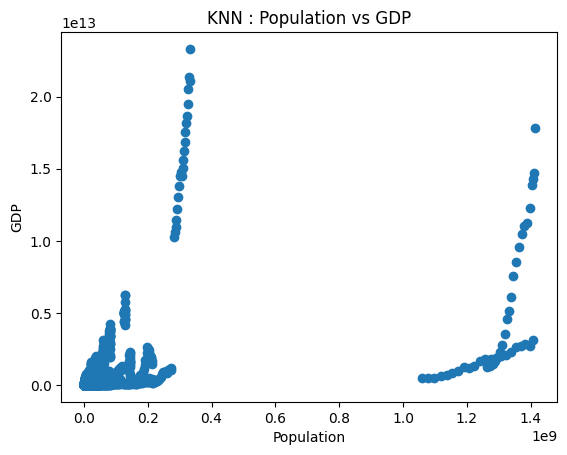

In [79]:
# KNN Actual graph shown
import matplotlib.pyplot as plt

plt.scatter(df["PopTotal"],df["GDP"])
plt.xlabel("Population")
plt.ylabel("GDP")
plt.title("KNN : Population vs GDP")
plt.show()

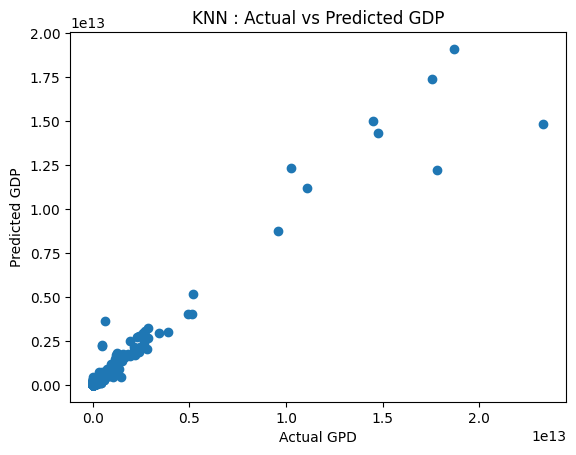

In [80]:
# KNN Predicted graph shown

plt.scatter(y_test,y_pred)
plt.xlabel("Actual GPD")
plt.ylabel("Predicted GDP")
plt.title("KNN : Actual vs Predicted GDP")
plt.show()